# Этап 1. Сбор и обработка данных

Ноутбук идёт **строго по методичке AITU**: табл. 7 «Data collection» и табл. 8 «Data processing».
Номер раздела = номер шага методички. Весь код — в `src/` (`src/pipeline.py` связывает шаги),
ноутбук только вызывает шаги по очереди и показывает результат.

Результаты сохраняются на Drive в `thesis/outputs/stage1_data/`:
`quality/` (проблемы данных), `tables/` (CSV), `figures/` (PNG, 300 dpi), `report.html` и `report.md`.

То же самое одной командой, без ноутбука: `python -m src.pipeline --thesis /content/drive/MyDrive/thesis`

## 0. Настройка окружения

In [1]:
import os, sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive, userdata
    drive.mount('/content/drive')
    token = userdata.get('GH_TOKEN')
    !git clone -q https://{token}@github.com/zhannaa0/kazakh-hybrid-nlp.git /content/project 2>/dev/null || git -C /content/project pull -q
    %cd /content/project
    !pip install -q -r requirements.txt
    PROJECT = Path('/content/project')
    THESIS = Path('/content/drive/MyDrive/thesis')
else:                                   # запуск на своём компьютере
    PROJECT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
    THESIS = Path(os.environ.get('THESIS_DIR', PROJECT.parent / 'thesis'))
sys.path.insert(0, str(PROJECT))

Mounted at /content/drive
/content/project


In [2]:
import json
import pandas as pd
from IPython.display import display, Image, Markdown

from src import pipeline as P
from src.data.collect import SOURCES

pd.set_option('display.float_format', '{:,.3f}'.format)
pd.set_option('display.max_colwidth', 80)
ctx = P.Context(THESIS)
print('исходные данные :', ctx.raw)
print('результаты      :', ctx.out)

исходные данные : /content/drive/MyDrive/thesis/data
результаты      : /content/drive/MyDrive/thesis/outputs/stage1_data


# Таблица 7. Data collection

### 7.1 Defining a data type
Тексты на казахском с **категориальной разметкой каждого токена**: теги сущностей IOB2 (25 типов),
части речи UPOS (17), морфологические признаки UD FEATS. Вход качественный (текст), в анализе
превращается в количественные показатели: частоты меток, F1, accuracy.

### 7.2 Careful planning
План из этапов 0–5 (данные → rule-based → нейросеть → гибрид → сравнение). Ограничения: нет бюджета
на новую разметку, бесплатный Colab (GPU T4, лимит сессий), работа по вечерам. Отсюда — готовые
корпуса, один общий трансформер, обработка данных на CPU.

### 7.3 Selecting data collection methods
**Вторичные данные — эталонные размеченные корпуса.** Плюсы: экспертная разметка, сравнимость с
опубликованными результатами, бесплатно. Минусы: фиксированные схемы разметки, жанр (новости,
госсайты), малый UD-KTB, пересечение train/test в KazNERD. Отклонено: собственная разметка
(время, стоимость), «серебряные» данные вроде WikiANN (шумная разметка).

### 7.4 Development of tools
Вместо анкеты инструмент исследования — код: конвейер данных (`src/data`), единый скрипт оценки
для всех 9 комбинаций задача × метод с фиксированными метриками (`src/eval`), автотесты (`tests`).

### 7.5 Data collection
Источники и **зафиксированные версии** (`src/data/collect.py`). Каждый файл сверяется с эталонным
SHA-256: если файл на Drive отличается от того, на котором получены результаты, шаг остановится.
Чтобы скачать недостающие файлы автоматически: `P.step_collect(ctx, download=True)`.

In [3]:
display(pd.DataFrame([{k: s[k] for k in ('name', 'version', 'license', 'repo', 'citation')}
                      for s in SOURCES.values()]))
P.step_collect(ctx, download=False)

,name,version,license,repo,citation
0,KazNERD,commit bd4333d (2025-01-15),CC BY 4.0,https://github.com/IS2AI/KazNERD,"Yeshpanov et al., 2022. KazNERD: Kazakh Named Entity Recognition Dataset. LREC."
1,UD Kazakh-KTB,release r2.18,CC BY-SA 4.0,https://github.com/UniversalDependencies/UD_Kazakh-KTB,"Makazhanov et al., 2015; Tyers & Washington, 2015. UD Kazakh KTB."


,dataset,file,status
0,KazNERD,IOB2_train.txt,ok
1,KazNERD,IOB2_valid.txt,ok
2,KazNERD,IOB2_test.txt,ok
3,UD Kazakh-KTB,kk_ktb-ud-train.conllu,ok
4,UD Kazakh-KTB,kk_ktb-ud-test.conllu,ok


### 7.6–7.8 Processing, analysis, documentation
Подробно — в таблице 8 ниже. Анализ **результатов моделей** (7.7) появится, когда методы
начнут сохранять предсказания: `python -m src.eval.evaluate results/preds --significance`.

# Таблица 8. Data processing

### 8.1 Data quality check
Проверяем **исходные** файлы до любых изменений: ошибки формата, пропуски, несогласованности.
Однозначные ошибки исправляются на шаге 8.3; остальное только фиксируется (официальные сплиты
должны остаться сравнимыми со статьями). Полные списки — в `outputs/stage1_data/quality/`.

In [4]:
P.step_quality(ctx)

,KazNERD,UD-KTB
check,,
invalid IOB2 tags,16,0
duplicate sentences in train,1373,0
dev sentences also in train,274,0
test sentences also in train,302,0
sentences with conflicting labels,19,0
empty tokens or labels,0,0


In [5]:
print('Кандидаты в пропуски разметки NER (для ручной проверки):')
display(ctx.r['quality']['gaps'].head(10))
print('Противоречивая разметка одинаковых предложений:')
ctx.r['quality']['conflicts'].head(5)

Кандидаты в пропуски разметки NER (для ручной проверки):


,string,main_type,as_entity,as_O,share_unlabeled
0,Шығыс,ORGANISATION,7,41,0.854
1,Біз біргеміз,PROJECT,8,10,0.556
2,Жас кәсіпкер,PROJECT,28,8,0.222
3,алғашқы күні,DATE,5,7,0.583
4,Бір,CARDINAL,9,6,0.400
5,Ауыл,ORGANISATION,14,6,0.300
6,Өңірлерді дамыту,PROJECT,6,5,0.455
7,бұл күні,DATE,6,5,0.455
8,Президент,POSITION,593,4,0.007
9,Жастар,FACILITY,8,4,0.333


Противоречивая разметка одинаковых предложений:


,tokens,variants,ids
0,"Синоптиктердің айтуынша , осы апта аязды .",2,train:kaznerd-train-000913; train:kaznerd-train-025468
1,"Бас қаладағы Қордай көшесінде көпқабатты үй , 169-ыншы пәтер .",2,train:kaznerd-train-010175; train:kaznerd-train-024191
2,"Күні бойы , түні бойы суды аңдимыз .",2,train:kaznerd-train-011010; train:kaznerd-train-070920
3,Апат айтып келмейді .,2,train:kaznerd-train-011935; train:kaznerd-train-015024; train:kaznerd-train-...
4,"Ал Солтүстік Қазақстан , Павлодар , Қарағанды мен Шығыс Қазақстан облысын қа...",2,train:kaznerd-train-015083; train:kaznerd-train-068242


### 8.2 Coding and structuring · 8.3 Data transformation
- **Структура:** оба корпуса → единый JSONL (`id`, `tokens`, метки по токенам); многословные
  токены UD → синтаксические слова.
- **Кодирование:** метки → числа, словари строятся только по train (`label_maps.json`).
  Для FEATS два варианта: строка целиком или каждая категория отдельно.
- **Преобразования:** нормализация Unicode NFC; латинские буквы-двойники → кириллица;
  `I-X` без начала → `B-X`. Стандартизация и логарифм к категориальным меткам неприменимы.
- **Разбиения:** KazNERD — официальный сплит; UD-KTB — новый 80/10/10, стратифицированный
  по исходному тексту, seed 42.

In [6]:
manifest = P.step_prepare(ctx, seed=42)
display(pd.Series(manifest['label_space']).to_frame('число меток'))
display(pd.Series(manifest['cleaning']).to_frame('исправлений'))
ctx.r['cleaning_log'].sample(8, random_state=0)[['id', 'rule', 'before', 'after']]

,число меток
ner_tags,51
upos,17
feats_whole,319
feat_categories,18


,исправлений
homoglyph,76
iob2_repair,16


,id,rule,before,after
2,kaznerd-train-006691,homoglyph,Tвиттер,Твиттер
33,kaznerd-train-036181,homoglyph,елдерi,елдері
22,kaznerd-train-025526,iob2_repair,I-ORGANISATION,B-ORGANISATION
16,kaznerd-train-019914,homoglyph,Тацуxико,Тацухико
13,kaznerd-train-016953,iob2_repair,I-CONTACT,B-CONTACT
24,kaznerd-train-029393,homoglyph,мәлiметтер,мәліметтер
60,kaznerd-train-068663,homoglyph,Tвиттердегі,Твиттердегі
76,kaznerd-train-085715,homoglyph,iрi,ірі


In [7]:
# Как выглядит одно предложение в едином формате
s = ctx.r['udktb']['train'][0]
print(json.dumps({k: (v[:6] if isinstance(v, list) else v) for k, v in s.items()}, ensure_ascii=False, indent=1))

{
 "id": "sholpan.tagged.txt:1:0",
 "doc": "sholpan",
 "text": "Шолпан Сәрсенбайға шыққан жылы өзіндей жас келіншектермен аулақта кеңескенде: «Баласыз өмірдің қызығы жоқ қой», – деп аузымен ғана айтушы еді.",
 "tokens": [
  "Шолпан",
  "Сәрсенбайға",
  "шыққан",
  "жылы",
  "өзіндей",
  "жас"
 ],
 "lemmas": [
  "Шолпан",
  "Сәрсенбай",
  "шық",
  "жыл",
  "өз",
  "жас"
 ],
 "upos": [
  "PROPN",
  "PROPN",
  "VERB",
  "NOUN",
  "PRON",
  "ADJ"
 ],
 "feats": [
  "Case=Nom|Gender=Fem",
  "Case=Dat|Gender=Masc",
  "Tense=Past|VerbForm=Part",
  "Case=Nom|Number[psor]=Plur,Sing|Person[psor]=3",
  "Number[psor]=Plur,Sing|Person[psor]=3|PronType=Prs|Reflex=Yes",
  "_"
 ]
}


### 8.4 Aggregation and summation · 8.5 Statistical analysis
Агрегирование по сплитам, типам сущностей, частям речи, категориям признаков, исходным текстам,
длине предложений и частотным диапазонам; описательная статистика (доли, дисбаланс, энтропия,
выбросы по IQR, OOV). Все таблицы сохраняются в `tables/`.

In [8]:
P.step_analyse(ctx)
t = ctx.r['tables']
for name in ('split_sizes', 'class_imbalance', 'descriptive_statistics', 'sentence_length_outliers'):
    display(Markdown(f'**{name}**')); display(t[name])

**split_sizes**

,dataset,split,sentences,tokens,share_of_sentences
0,KazNERD,train,90228,1043305,0.801
1,KazNERD,dev,11167,129223,0.099
2,KazNERD,test,11307,129824,0.100
3,UD-KTB official,train,31,529,0.029
4,UD-KTB official,test,1047,10007,0.971
5,UD-KTB re-split,train,864,8320,0.801
6,UD-KTB re-split,dev,107,1106,0.099
7,UD-KTB re-split,test,107,1110,0.099


**class_imbalance**

,KazNERD entity types,UD-KTB UPOS
measure,,
classes,25,17
largest_class,CARDINAL,NOUN
largest_share,0.215,0.293
smallest_class,NON_HUMAN,SYM
smallest_count,6,1
imbalance_ratio,"3,925.167","2,438.000"
top3_share,0.529,0.646
classes_lt_1pct,8,4


**descriptive_statistics**

,count,mean,std,min,25%,50%,75%,95%,max,class_entropy_bits
dataset,,,,,,,,,,
KazNERD,"112,702.000",11.556,4.636,1.000,8.000,11.000,14.000,20.000,71.000,3.601
UD-KTB,"1,078.000",9.774,5.550,2.000,6.000,8.000,11.000,20.000,51.000,3.071


**sentence_length_outliers**

,mean,median,min,max,upper_fence,n_long_outliers,n_short_outliers,share_outliers
dataset,,,,,,,,
KazNERD,11.556,11.000,1,71,23.000,1685,0,0.015
UD-KTB,9.774,8.000,2,51,18.500,76,0,0.071


In [9]:
display(Markdown('**OOV и редкие слова**'))
display(pd.concat({'KazNERD': t['vocabulary_kaznerd'], 'UD-KTB': t['vocabulary_udktb']}))
display(Markdown('**Веса классов NER для функции потерь (если будем компенсировать дисбаланс)**'))
t['ner_class_weights'].sort_values('train_entities').head(8)

**OOV и редкие слова**

types  tokens  hapax_types_share  rare_le5_types_share  \
        split                                                           
KazNERD train  65507  862713              0.389                 0.762   
        dev    20503  106884                NaN                   NaN   
        test   20650  107419                NaN                   NaN   
UD-KTB  train   3636    6682              0.737                 0.957   
        dev      700     853                NaN                   NaN   
        test     738     901                NaN                   NaN   

               oov_token_rate  oov_type_rate  
        split                                 
KazNERD train           0.000          0.000  
        dev             0.048          0.195  
        test            0.048          0.196  
UD-KTB  train           0.000          0.000  
        dev             0.449          0.531  
        test            0.413          0.497

**Веса классов NER для функции потерь (если будем компенсировать дисбаланс)**

,train_entities,weight_inverse_sqrt,weight_inverse
entity_type,,,
NON_HUMAN,6,9.256,10.000
ADAGE,160,1.792,0.790
CONTACT,164,1.770,0.771
MISCELLANEOUS,194,1.628,0.652
LANGUAGE,352,1.208,0.359
LAW,425,1.100,0.298
PRODUCT,592,0.932,0.214
DISEASE,1032,0.706,0.123


### 8.6 Data visualisation
Данные **до и после** предобработки (рис. 1–3) и разведочный анализ (рис. 4–10).
PNG 300 dpi в `figures/` — готовы для диссертации.

**Figure 1.** Corrections applied during preprocessing

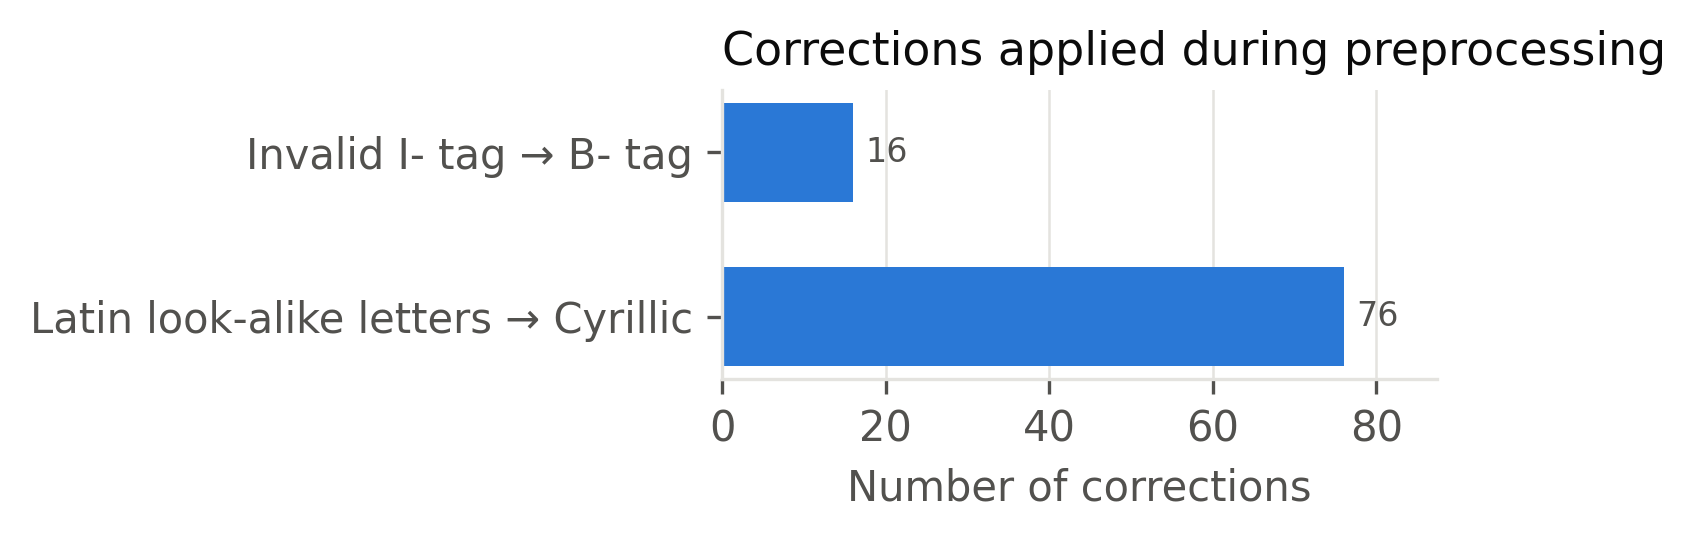

**Figure 2.** Sentences per split: KazNERD, UD-KTB official split and UD-KTB re-split

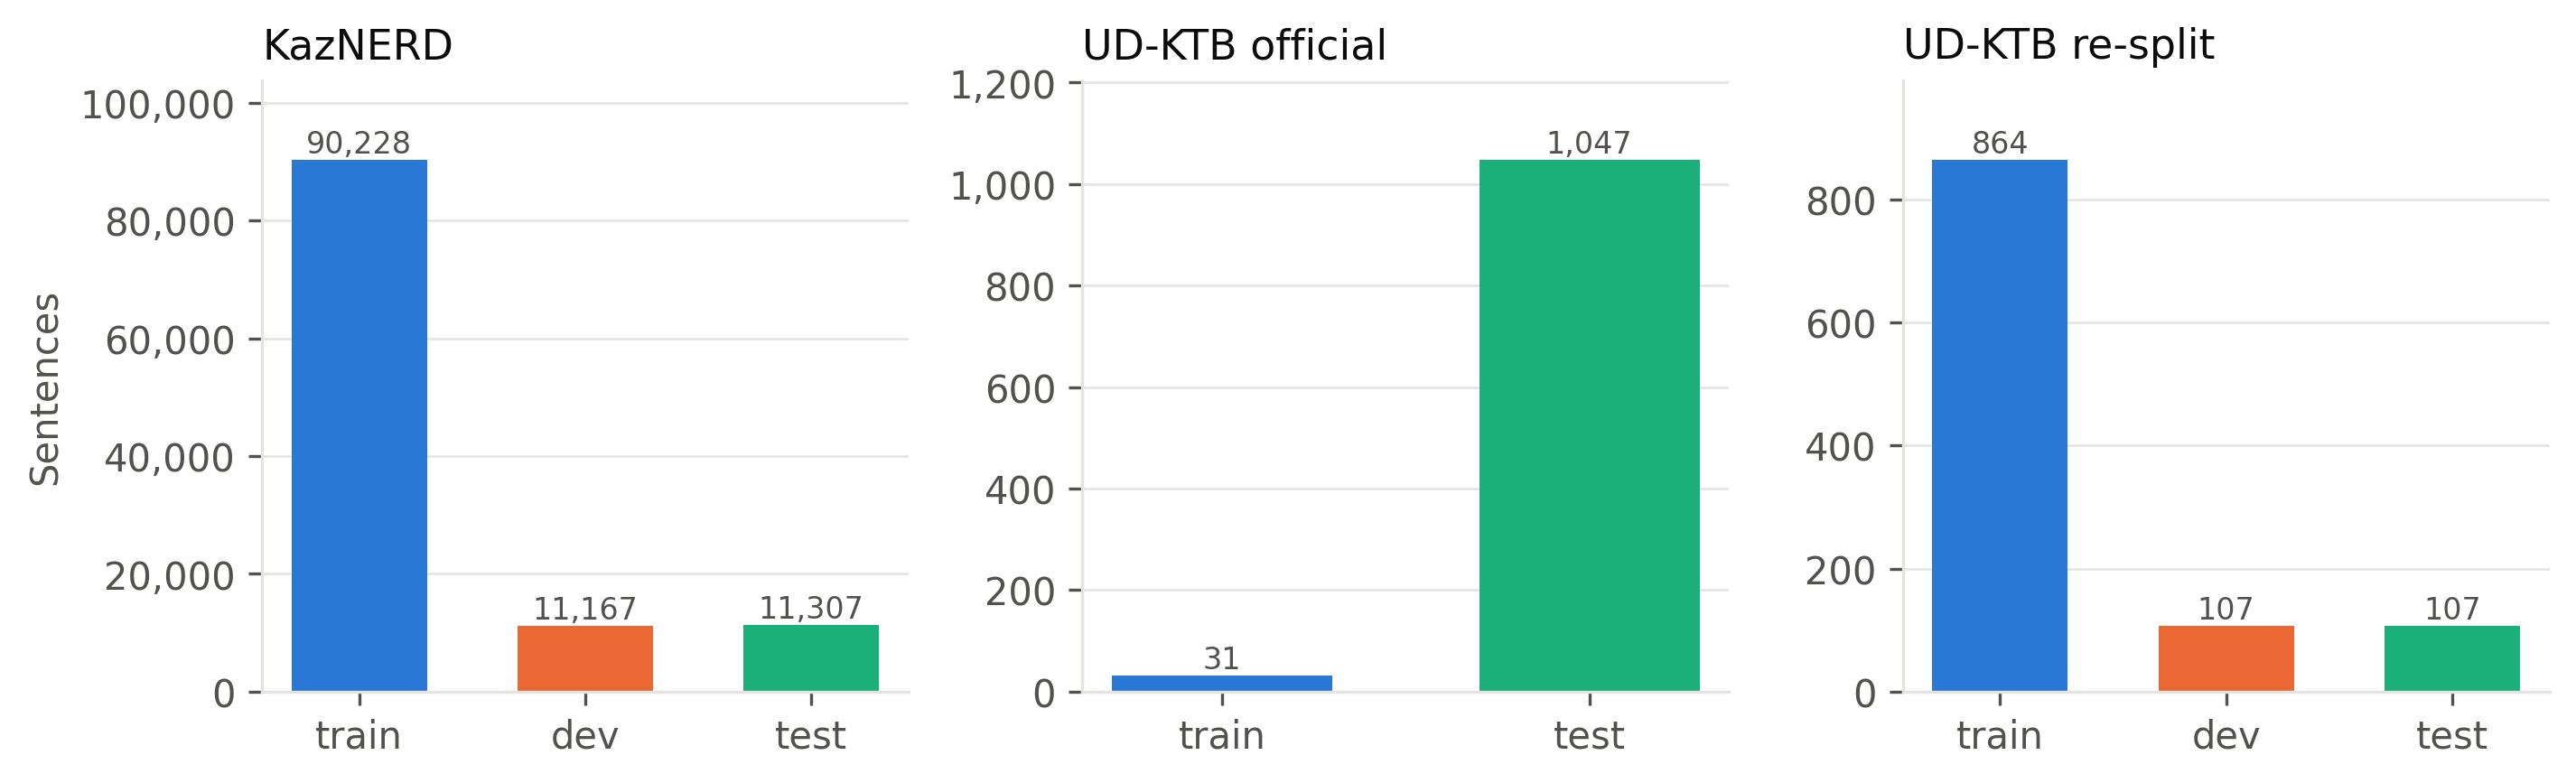

**Figure 3.** UD-KTB source texts by split, before and after re-splitting

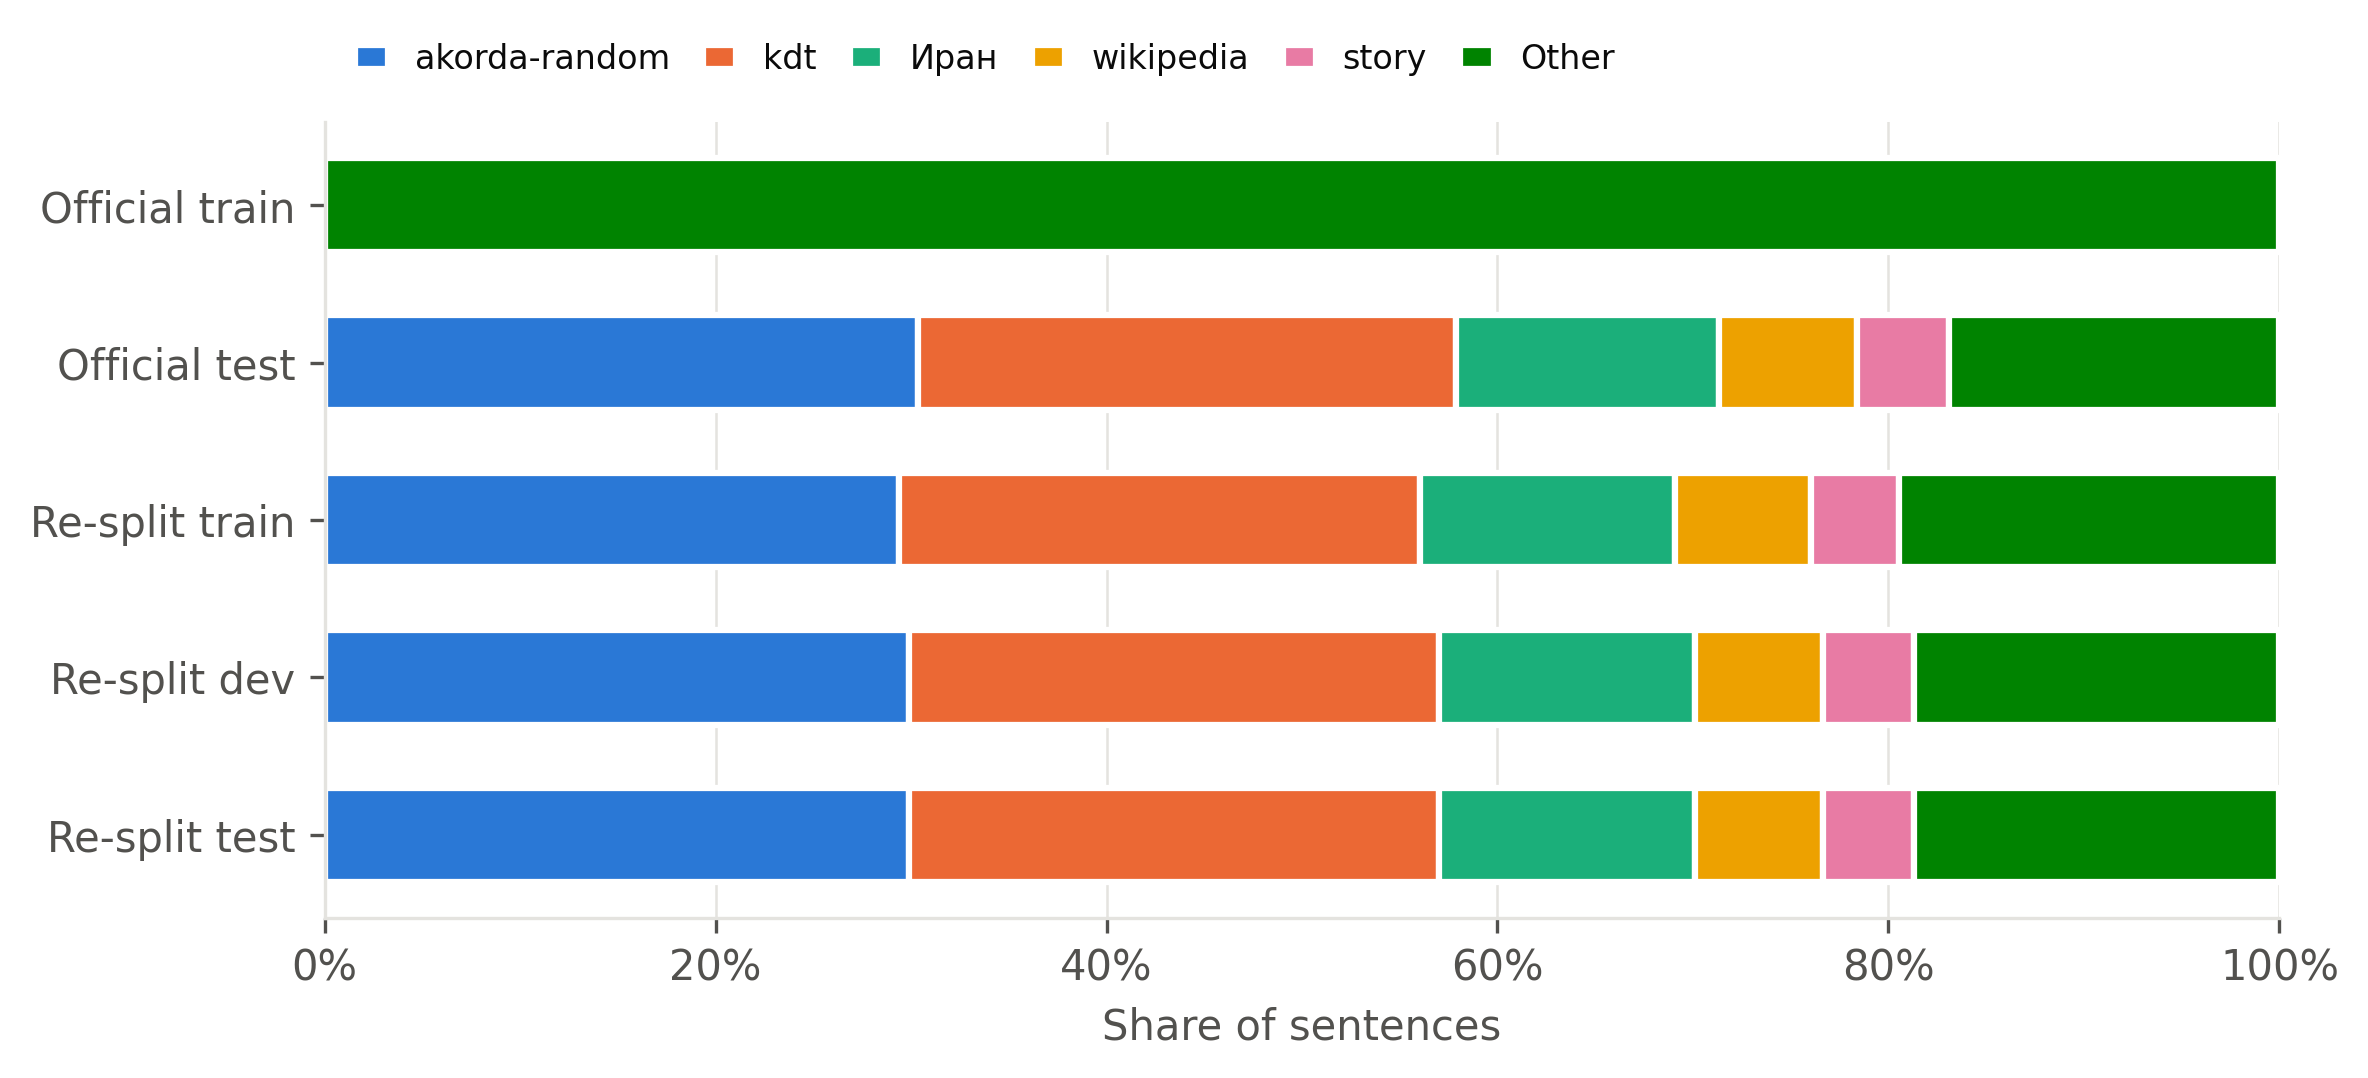

**Figure 4.** KazNERD entities per type in train (log scale)

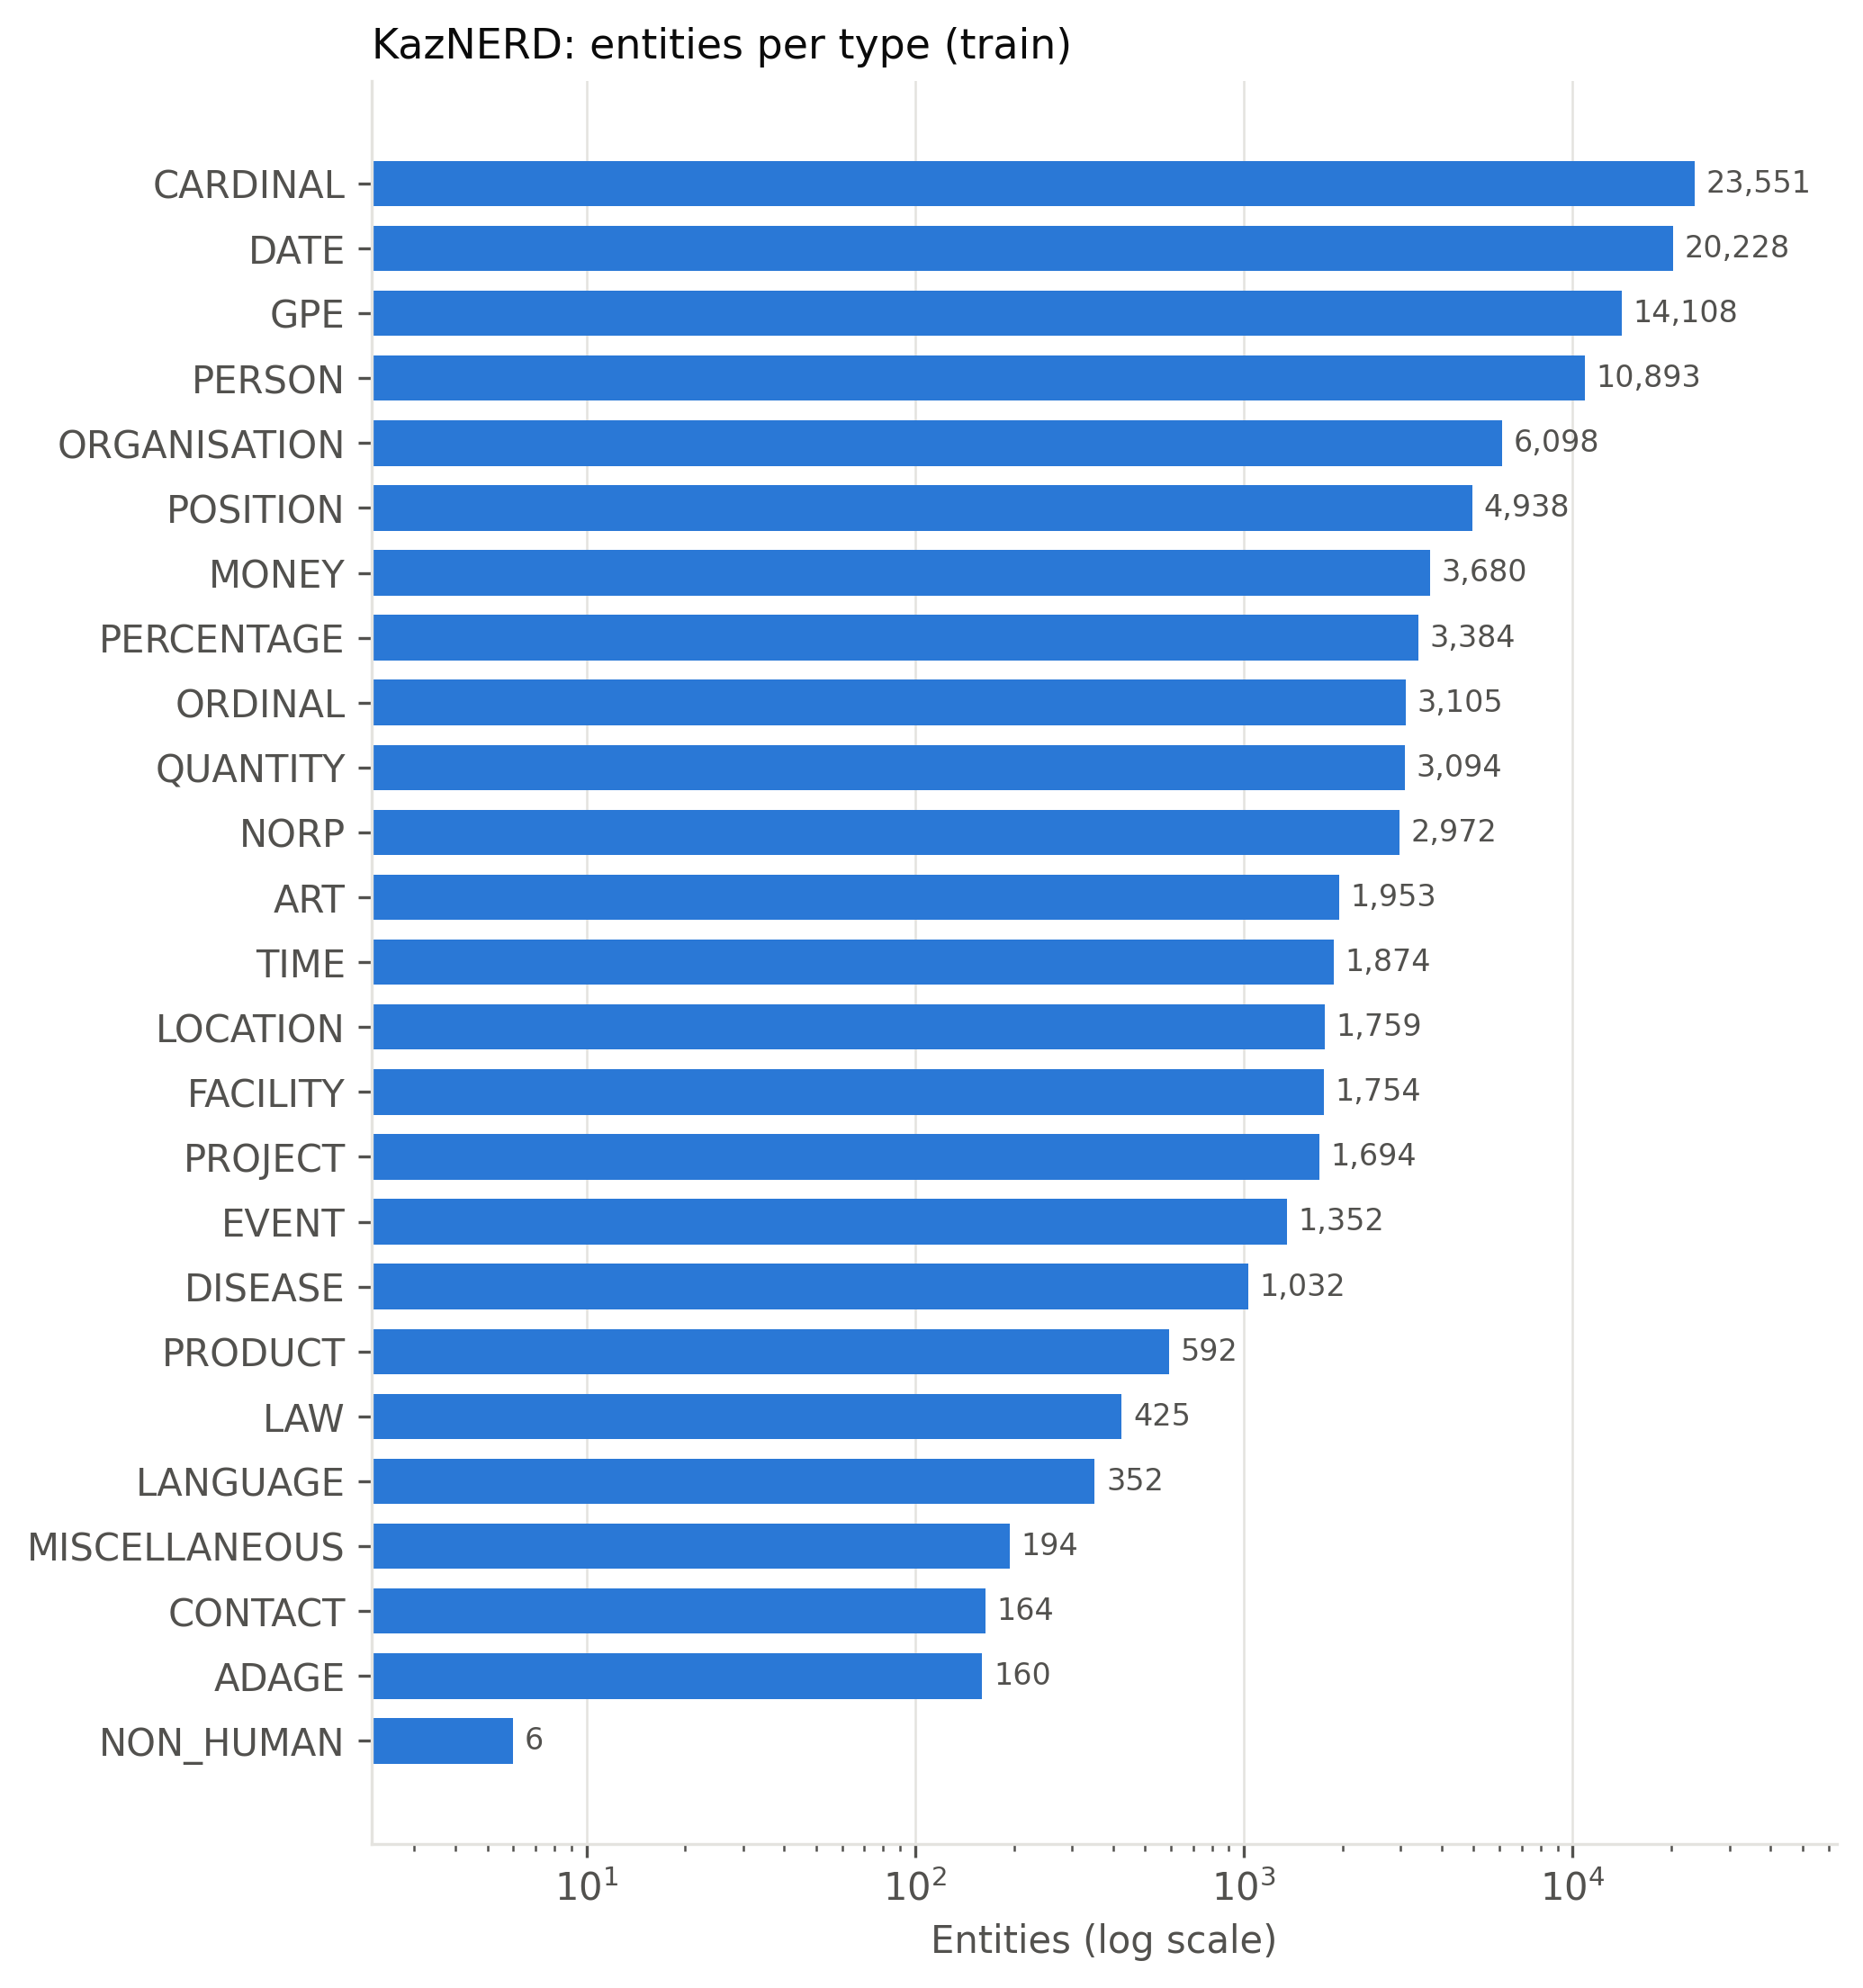

**Figure 5.** Share of each entity type in train, dev and test

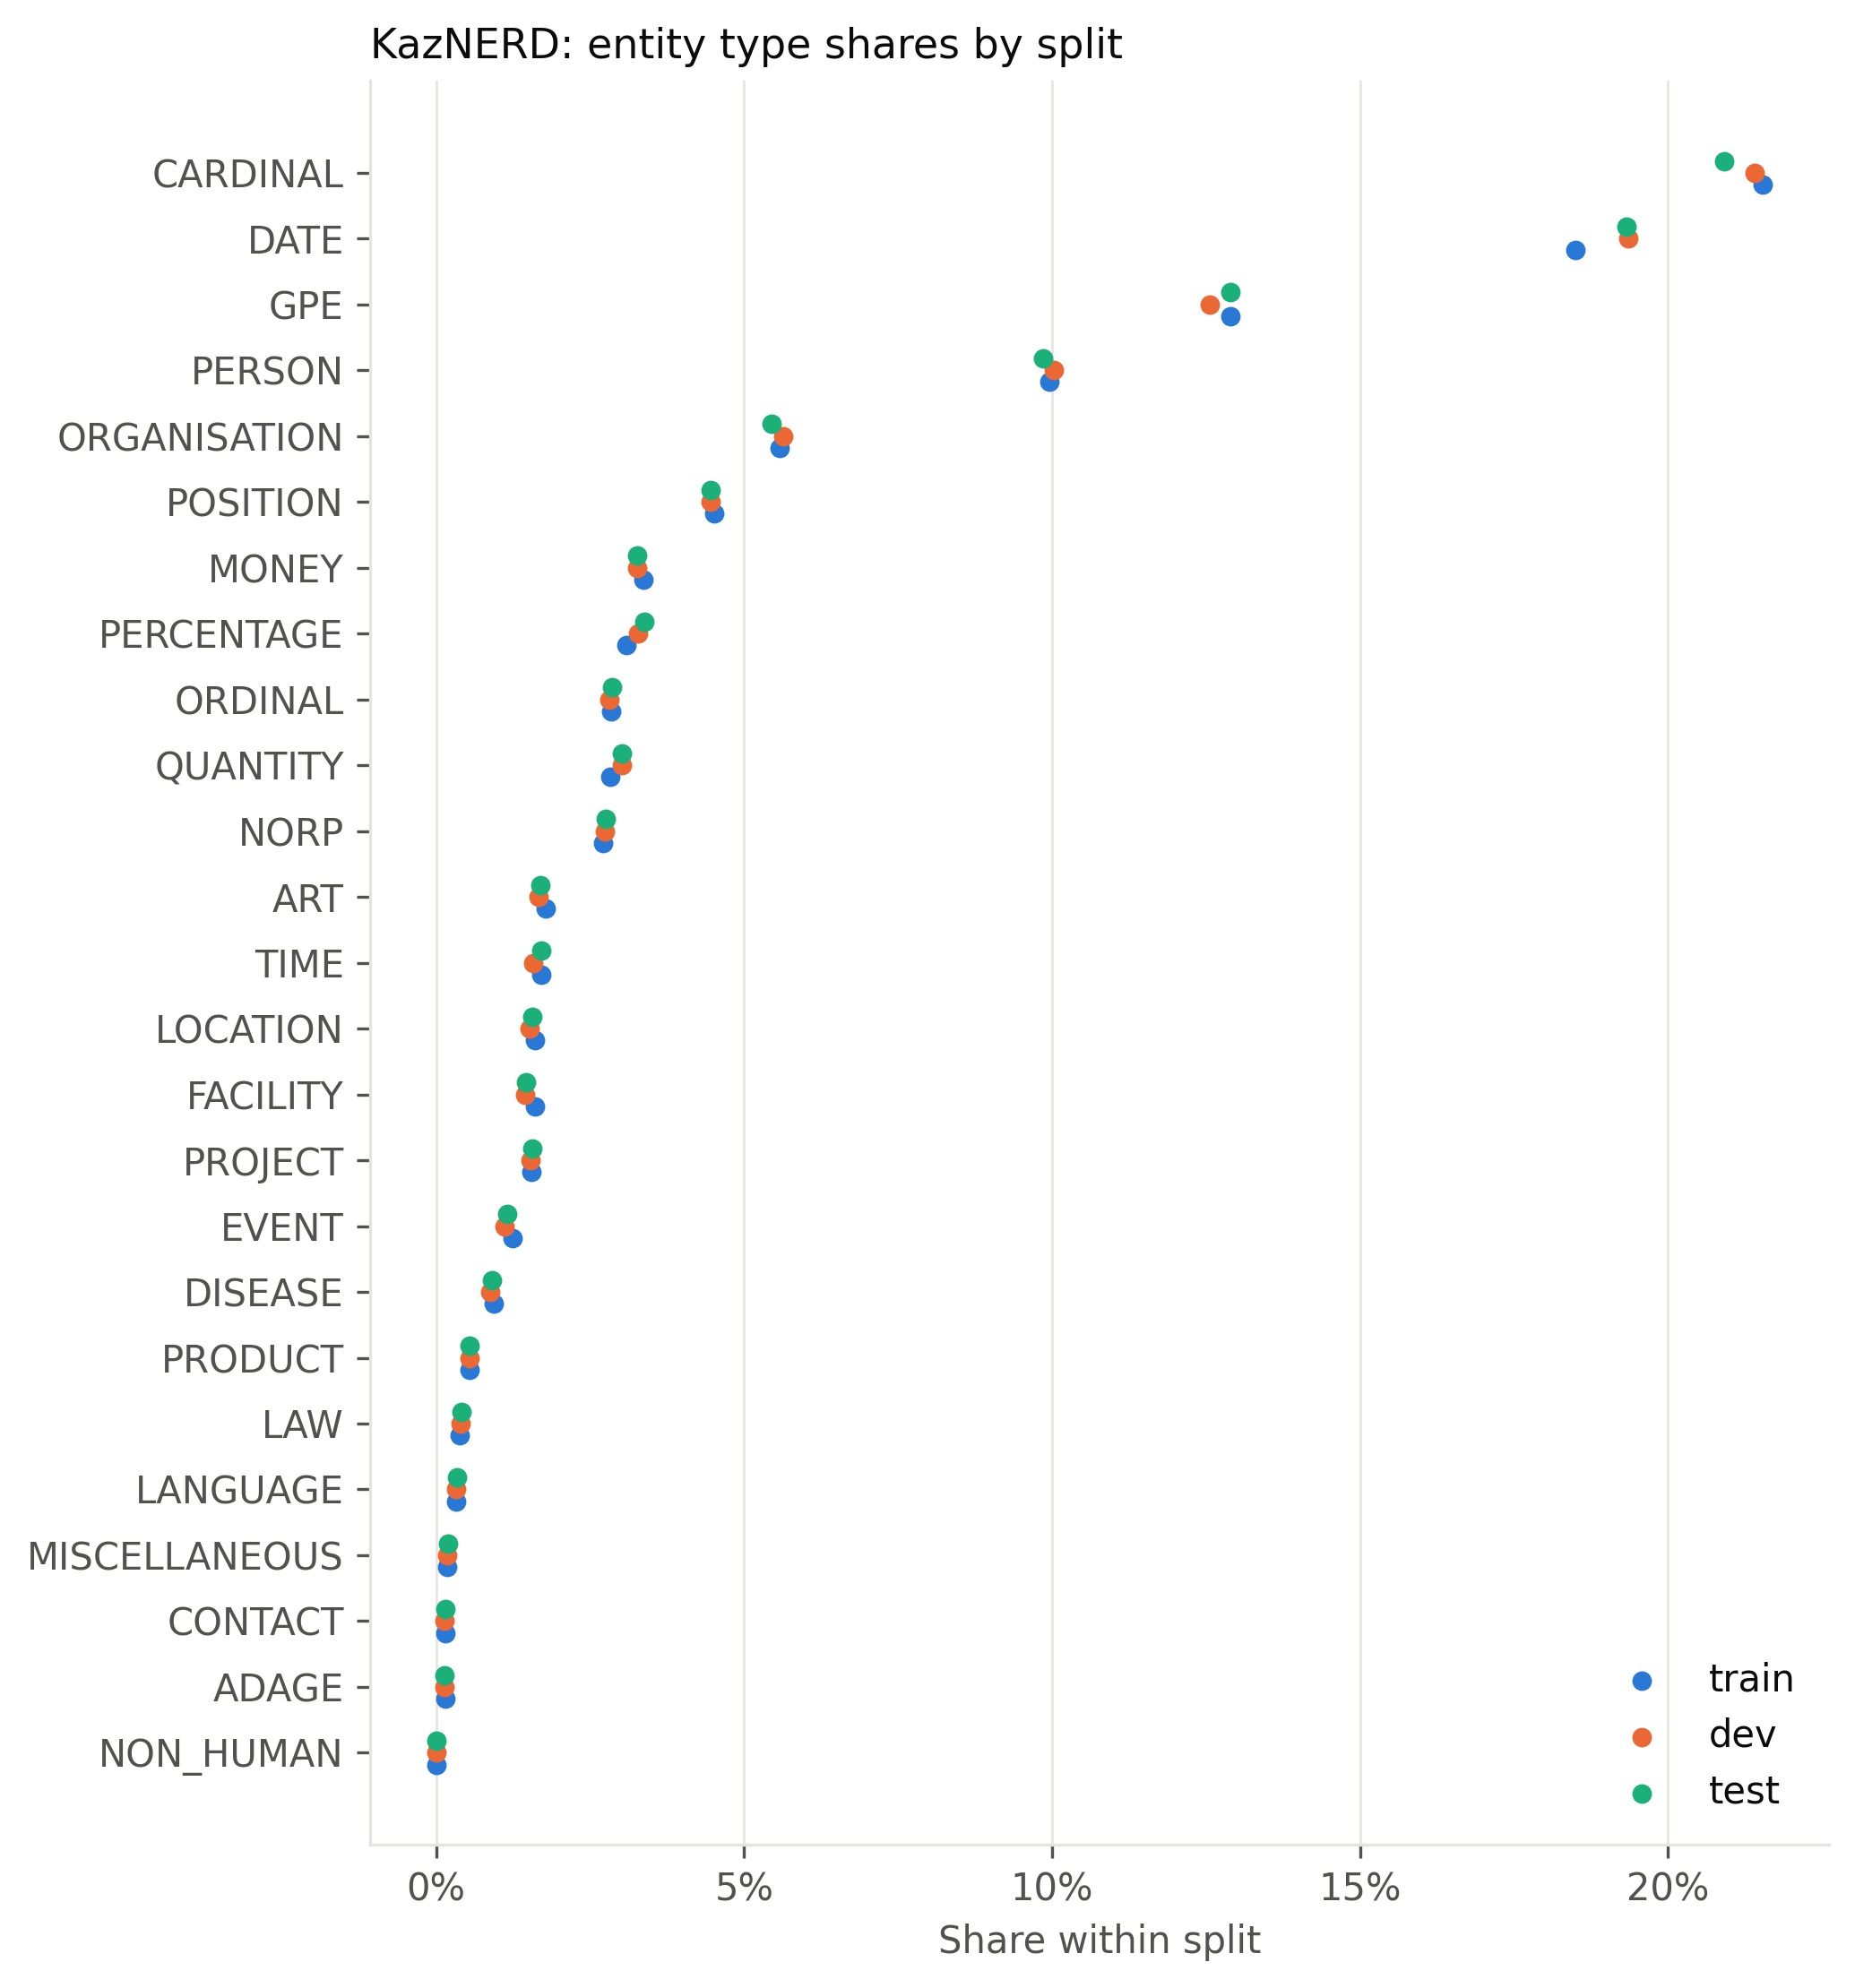

**Figure 6.** UD-KTB UPOS tags in train

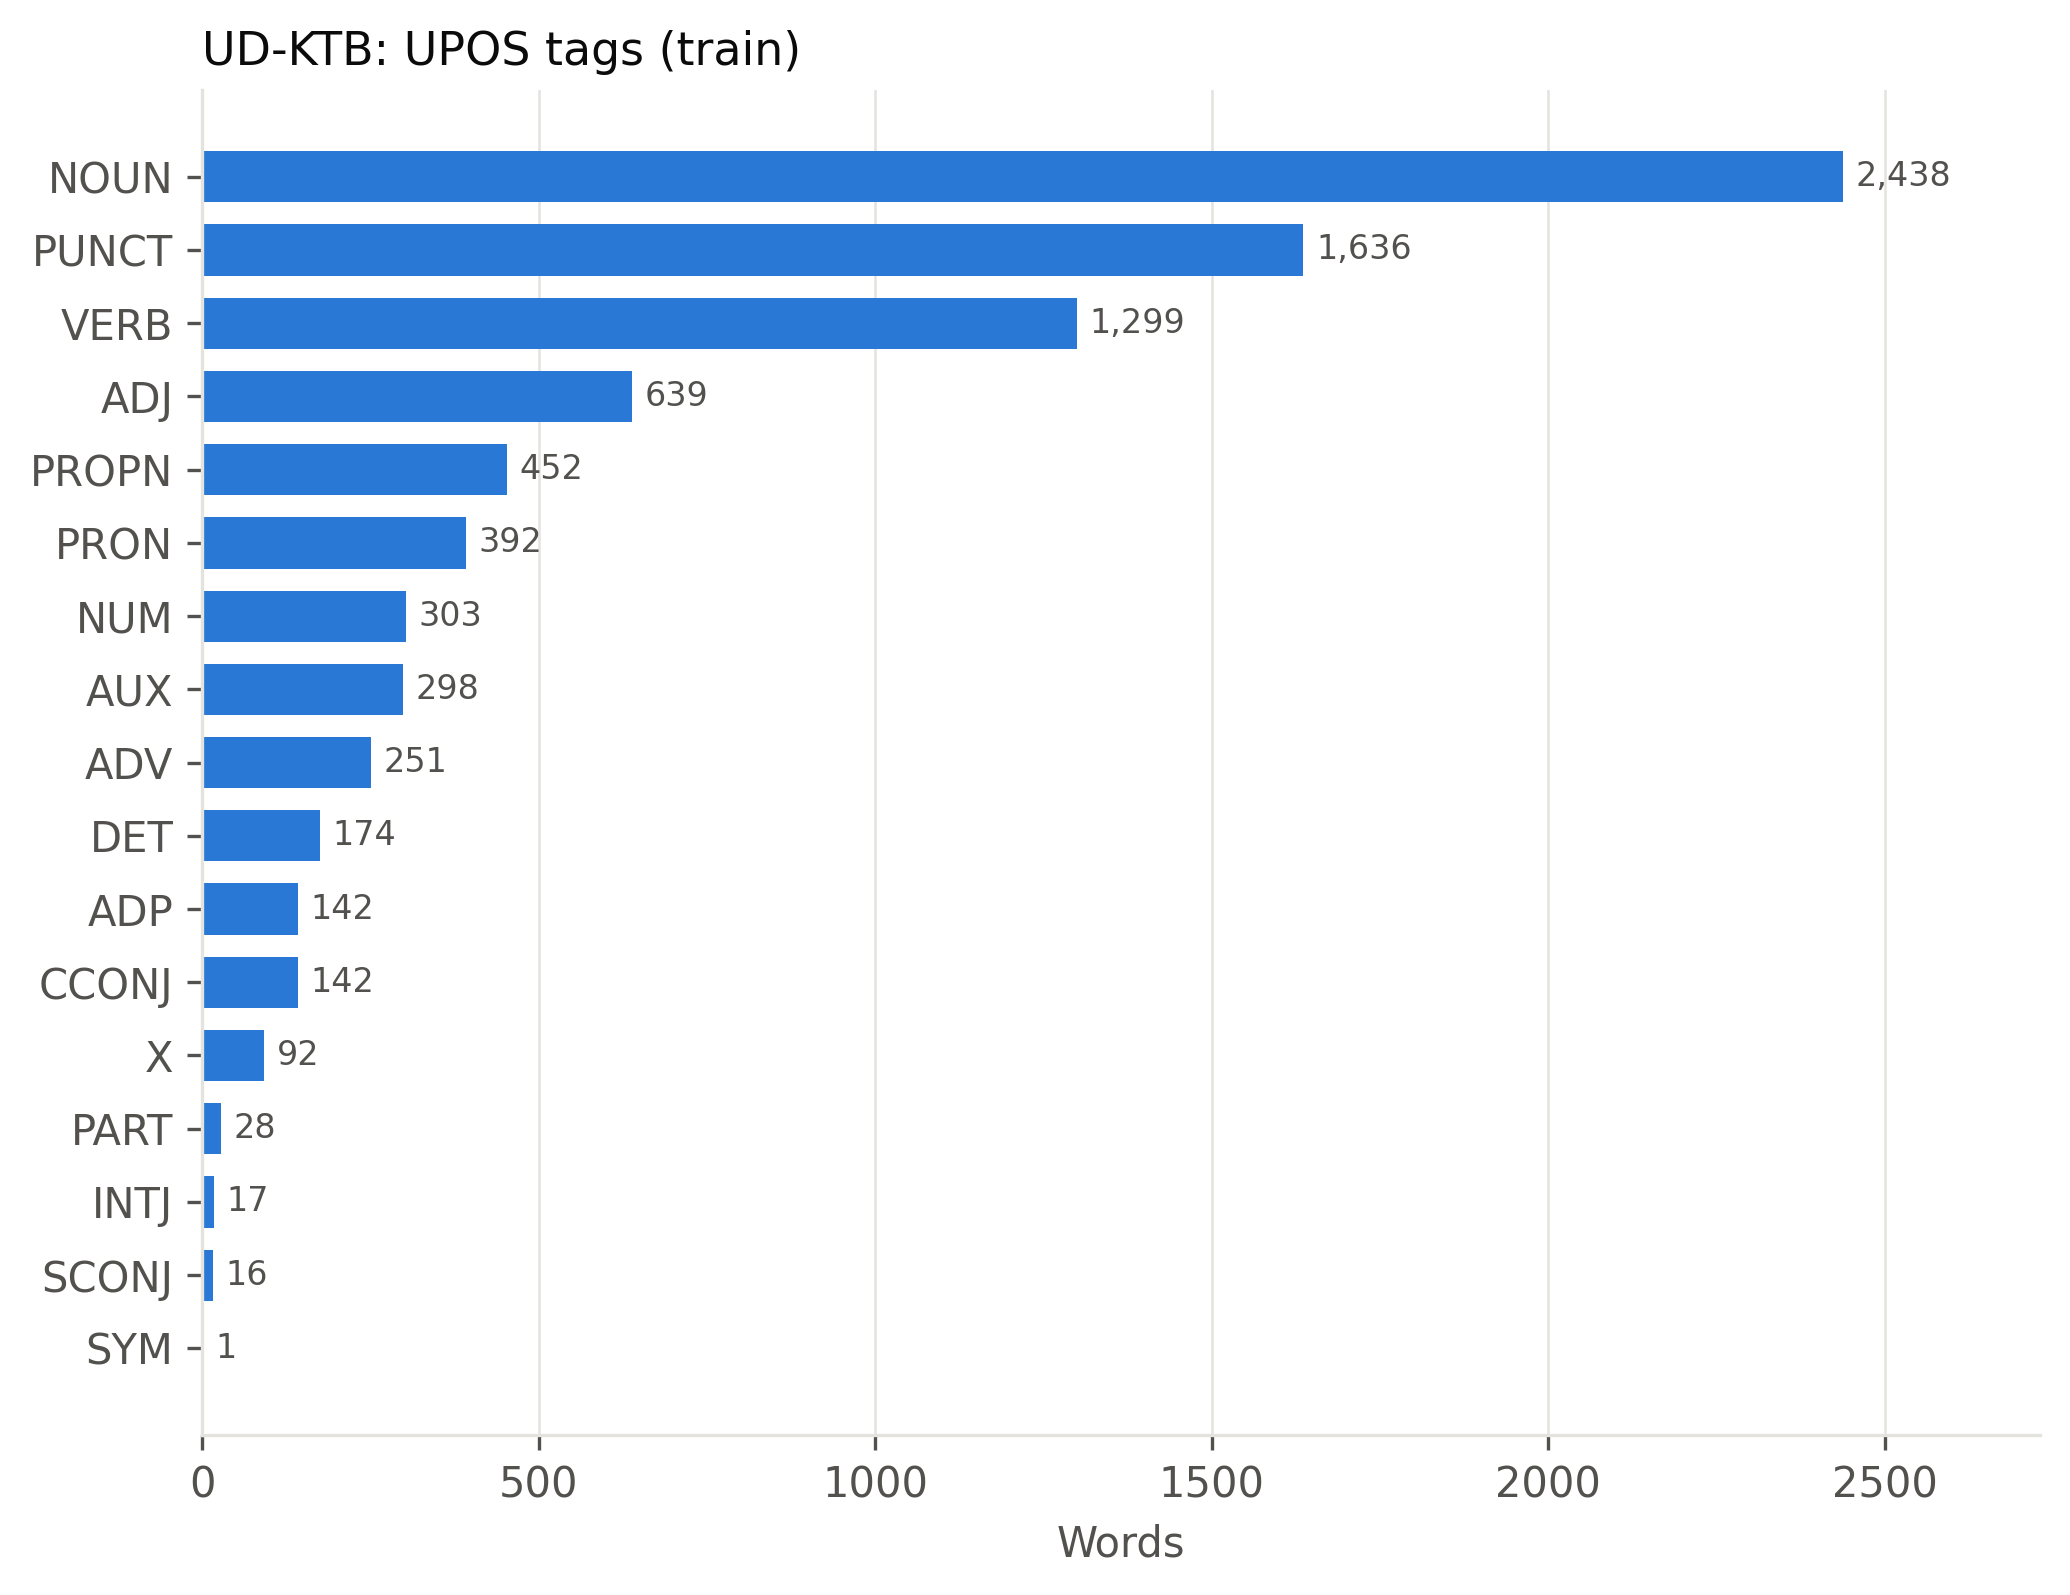

**Figure 7.** UD-KTB morphological categories in train

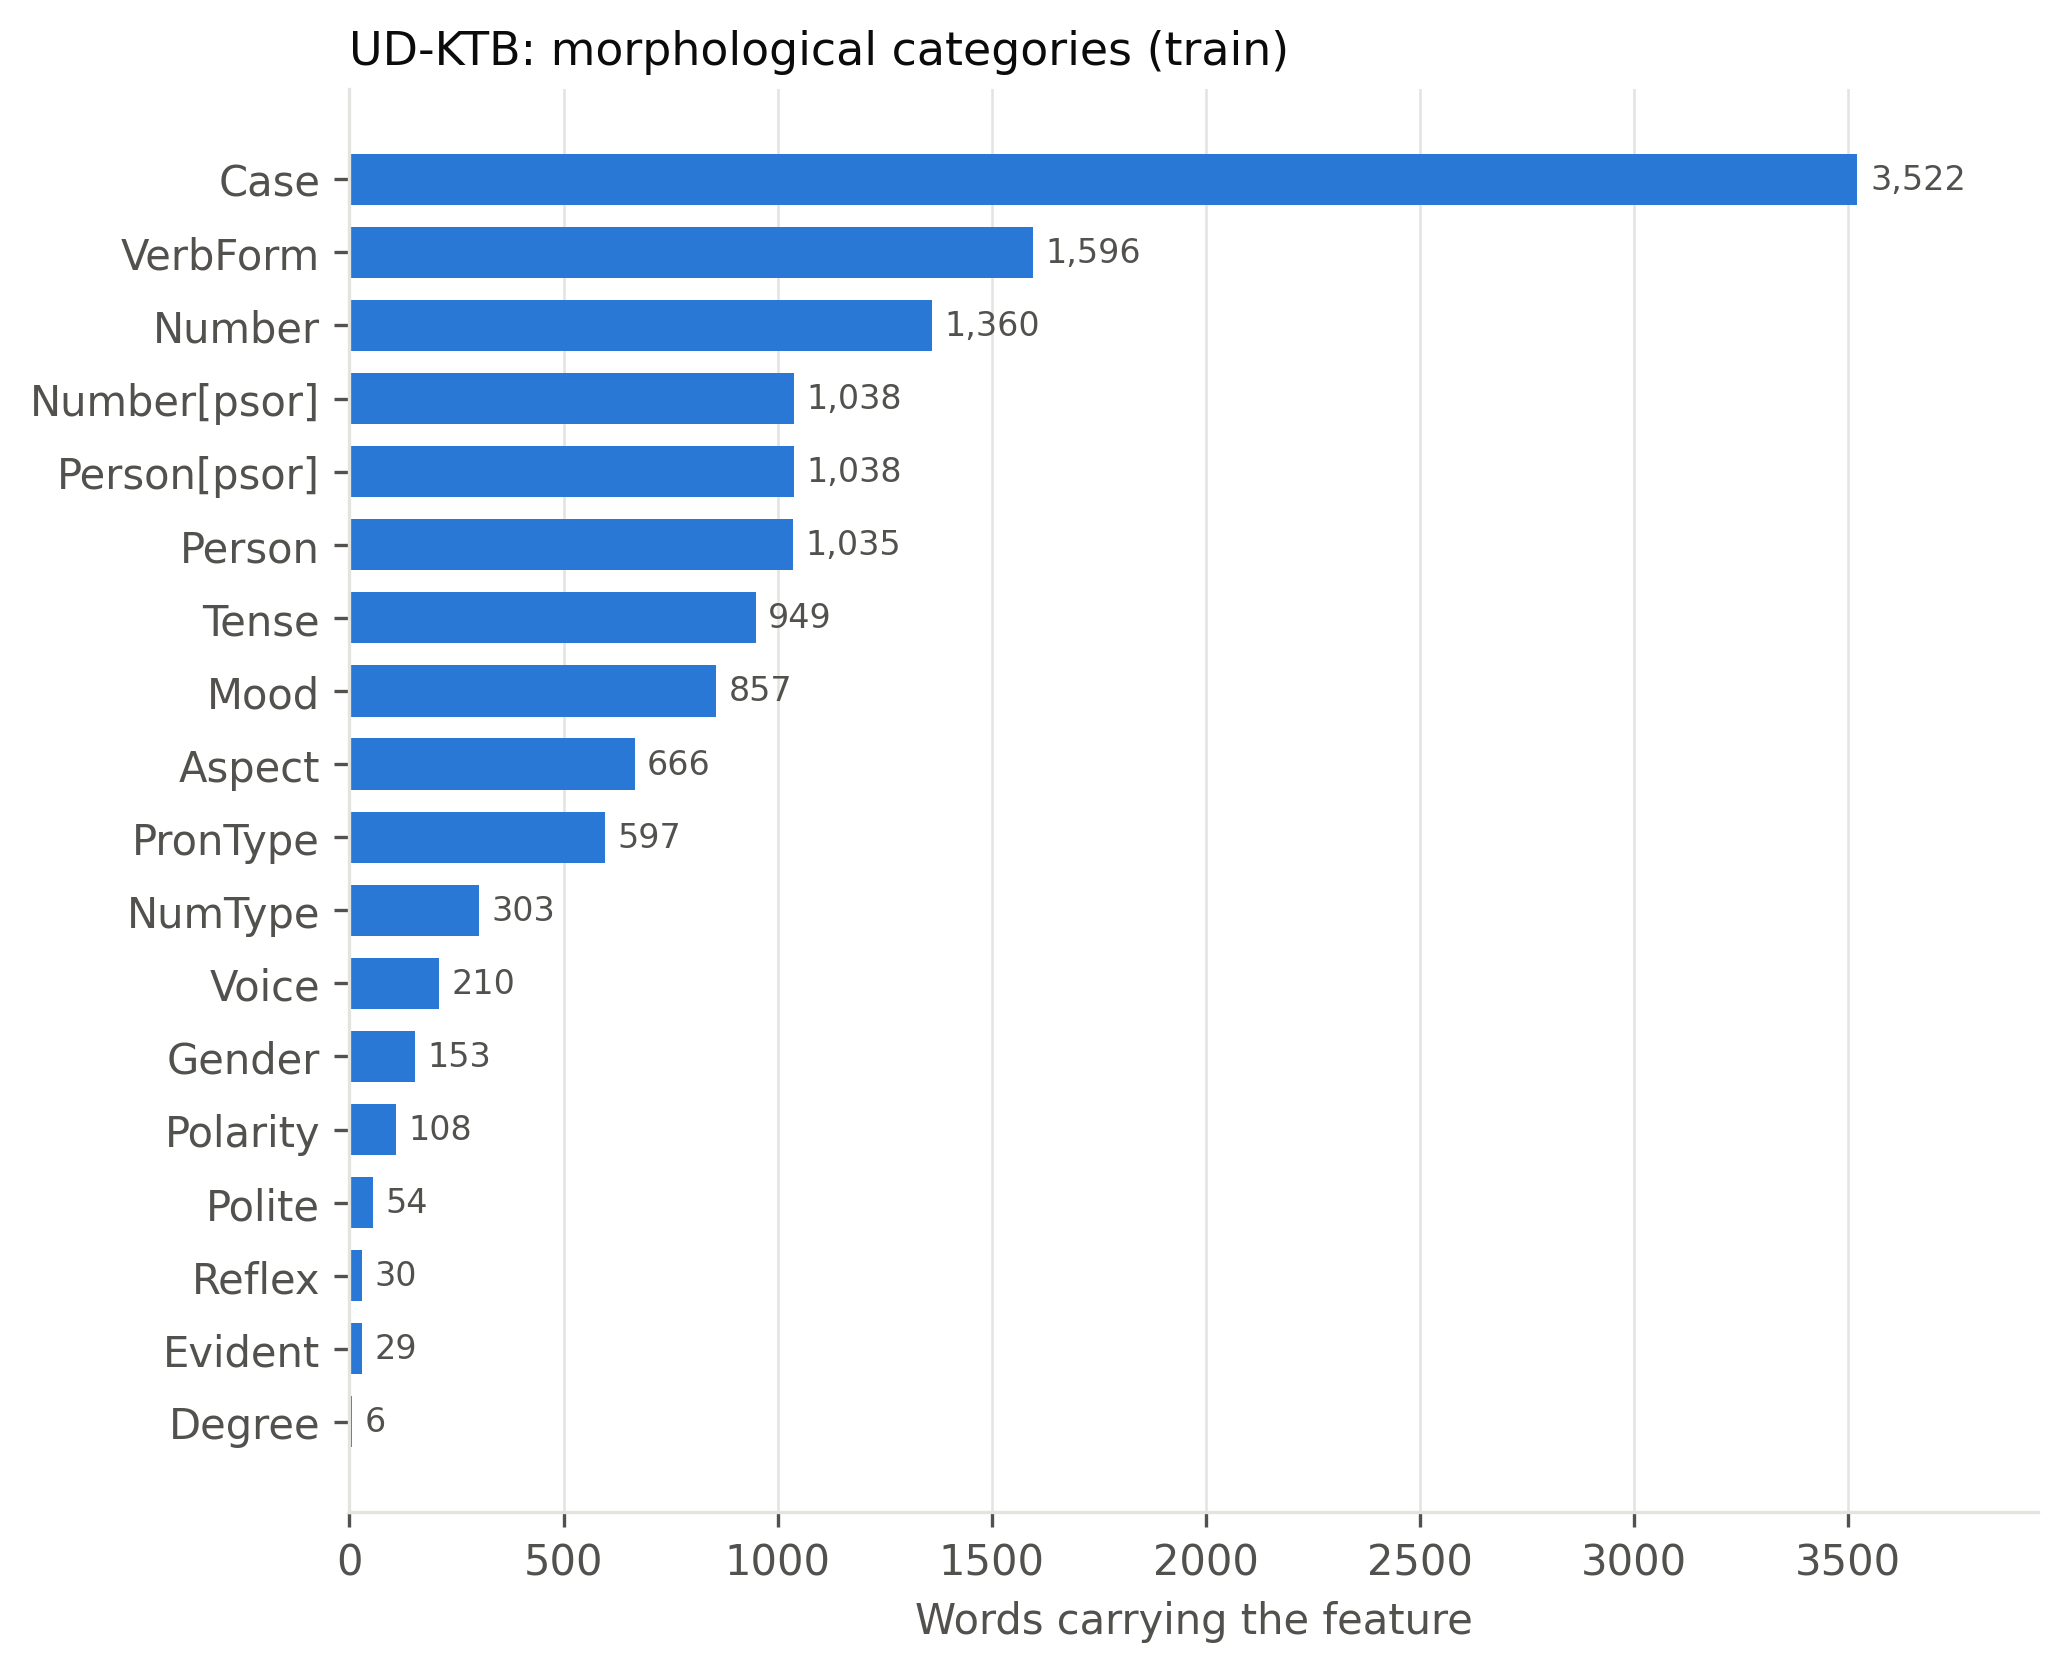

**Figure 8.** Sentence length distribution with median and IQR outlier fence

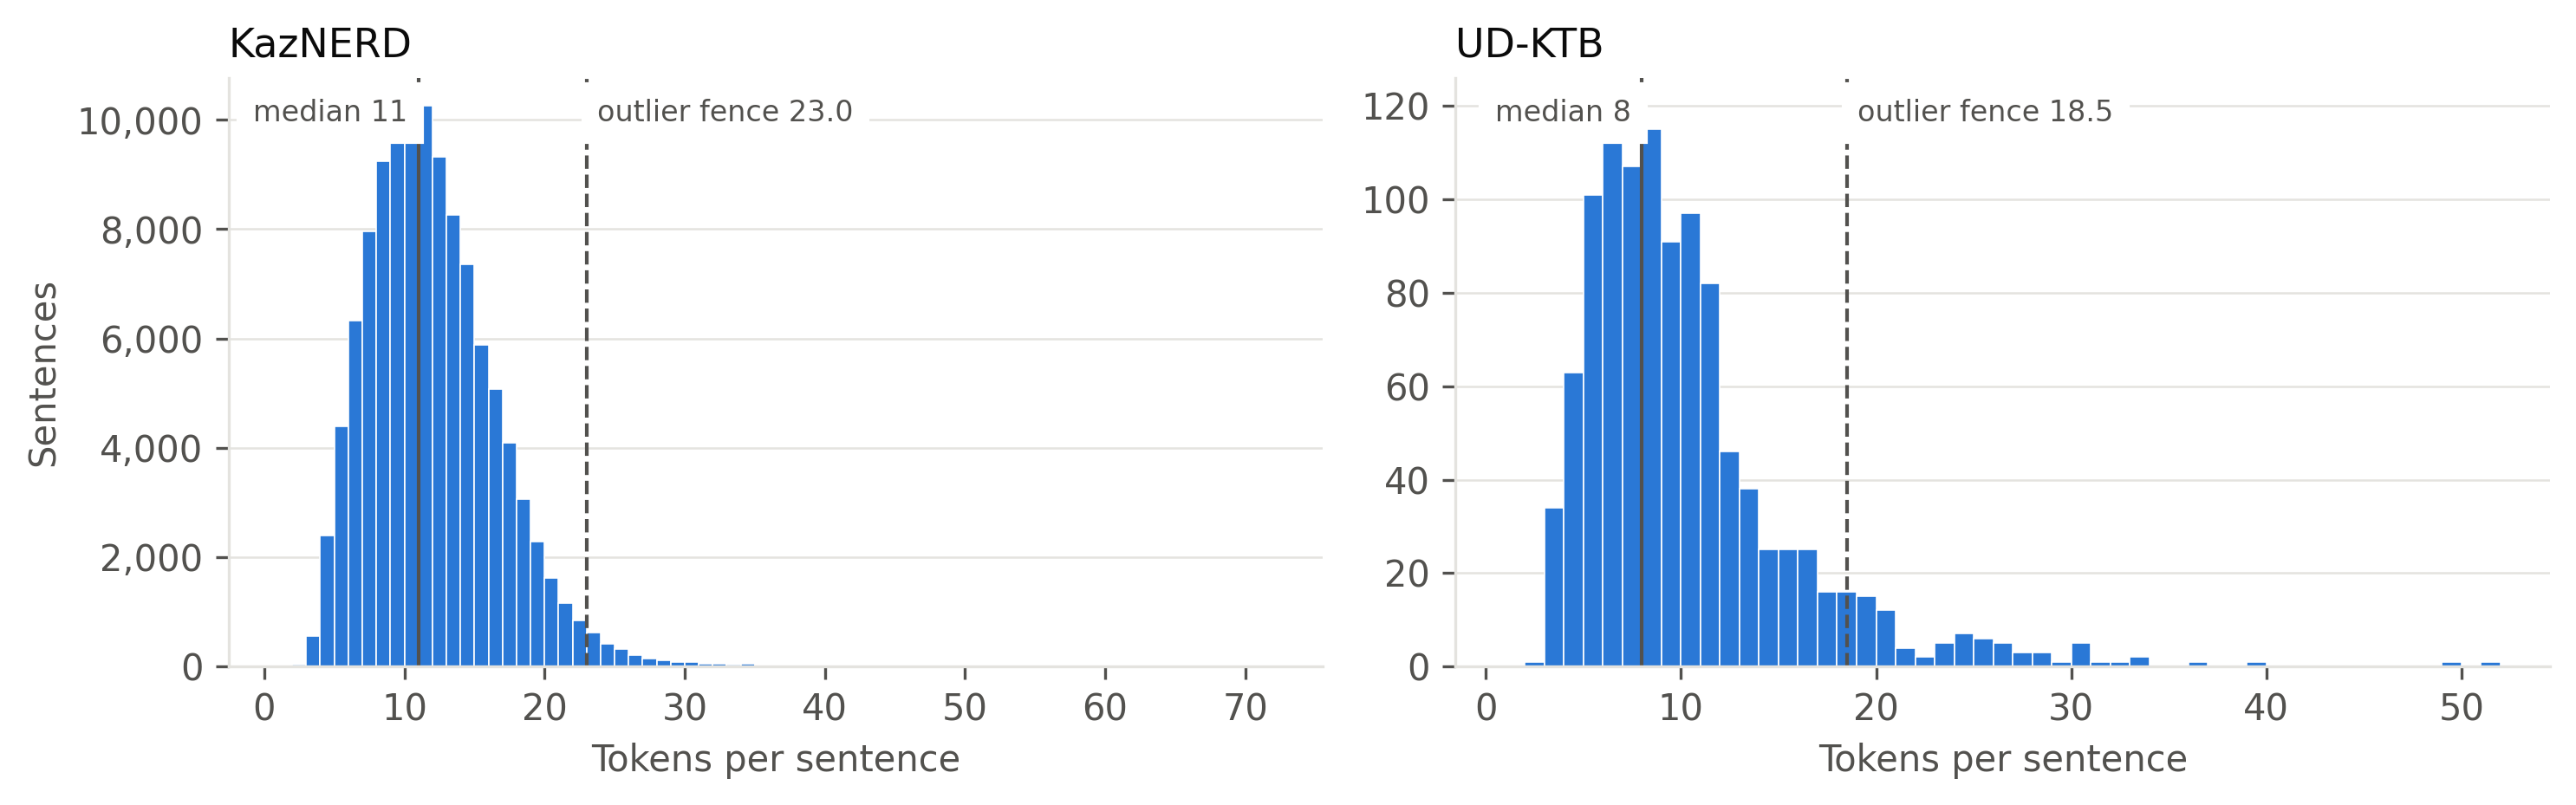

**Figure 9.** Word types and running words by frequency band in train

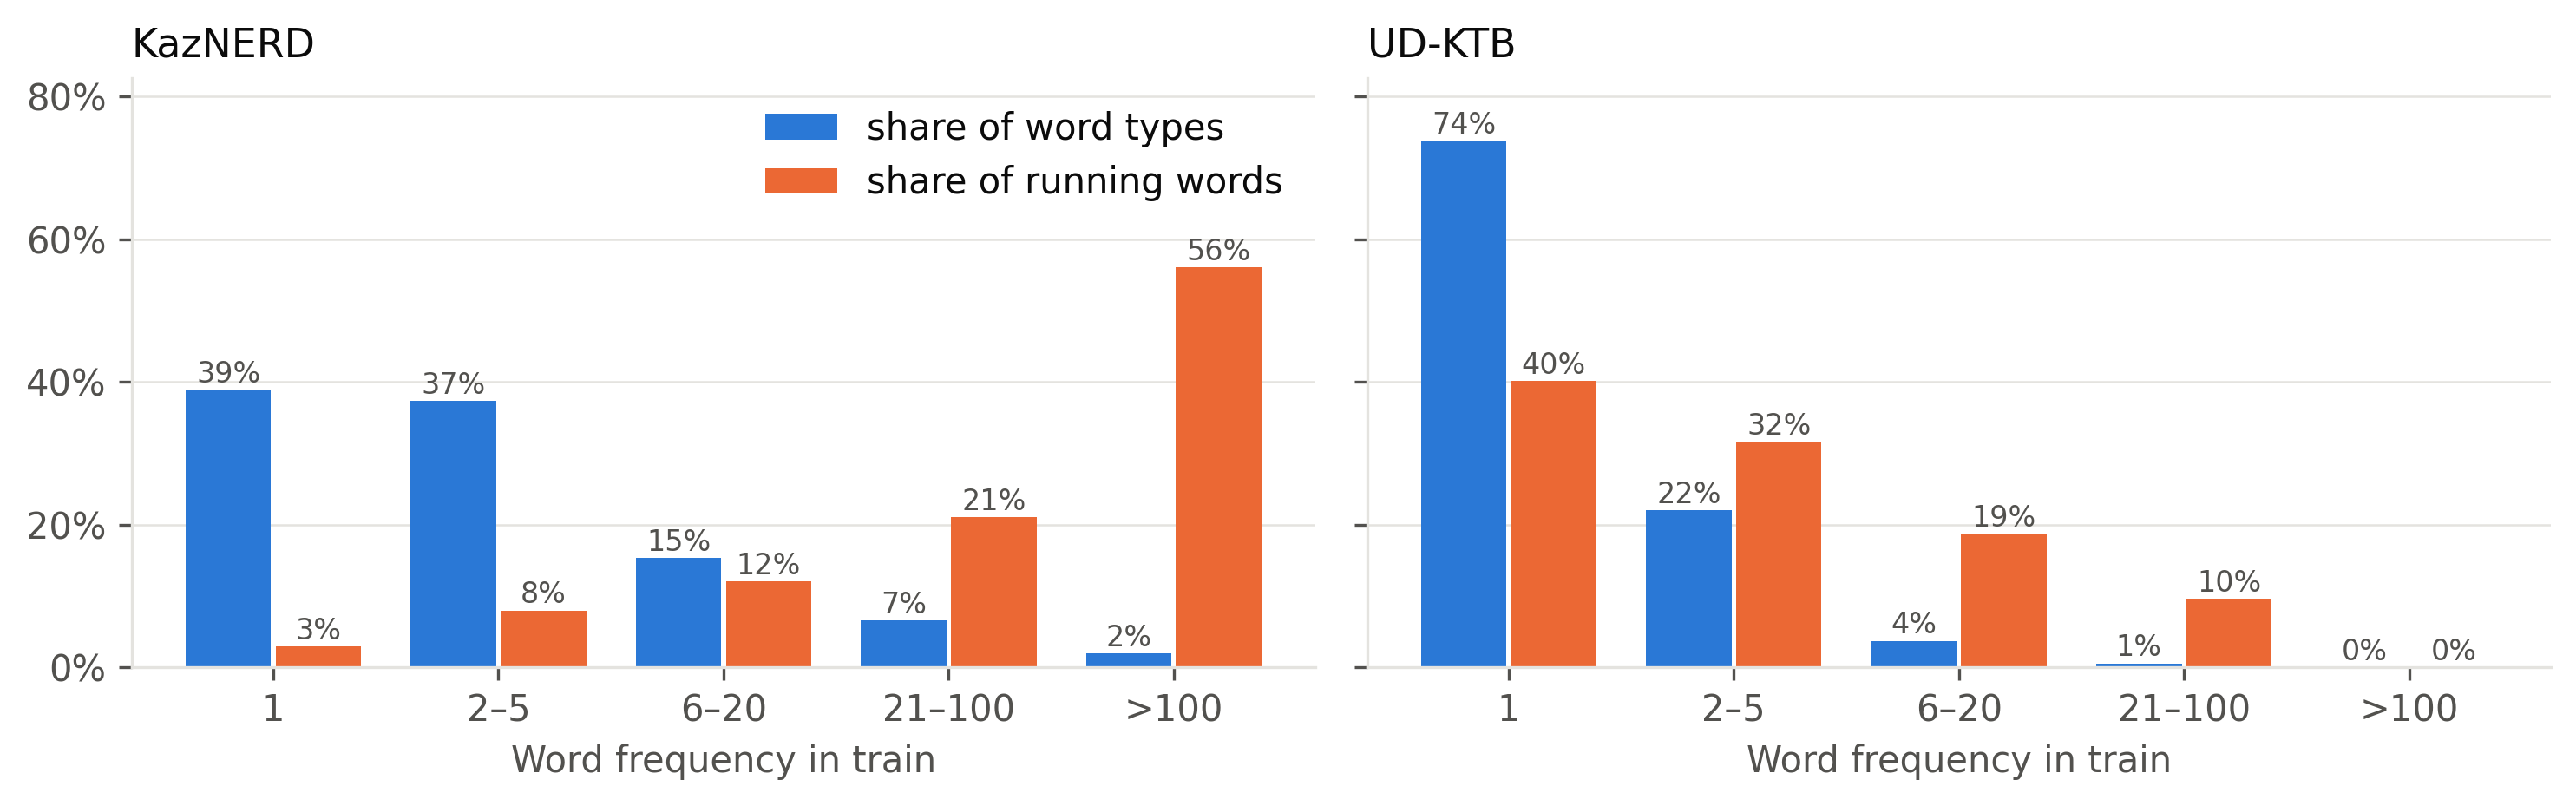

**Figure 10.** Share of running words in dev and test unseen in train

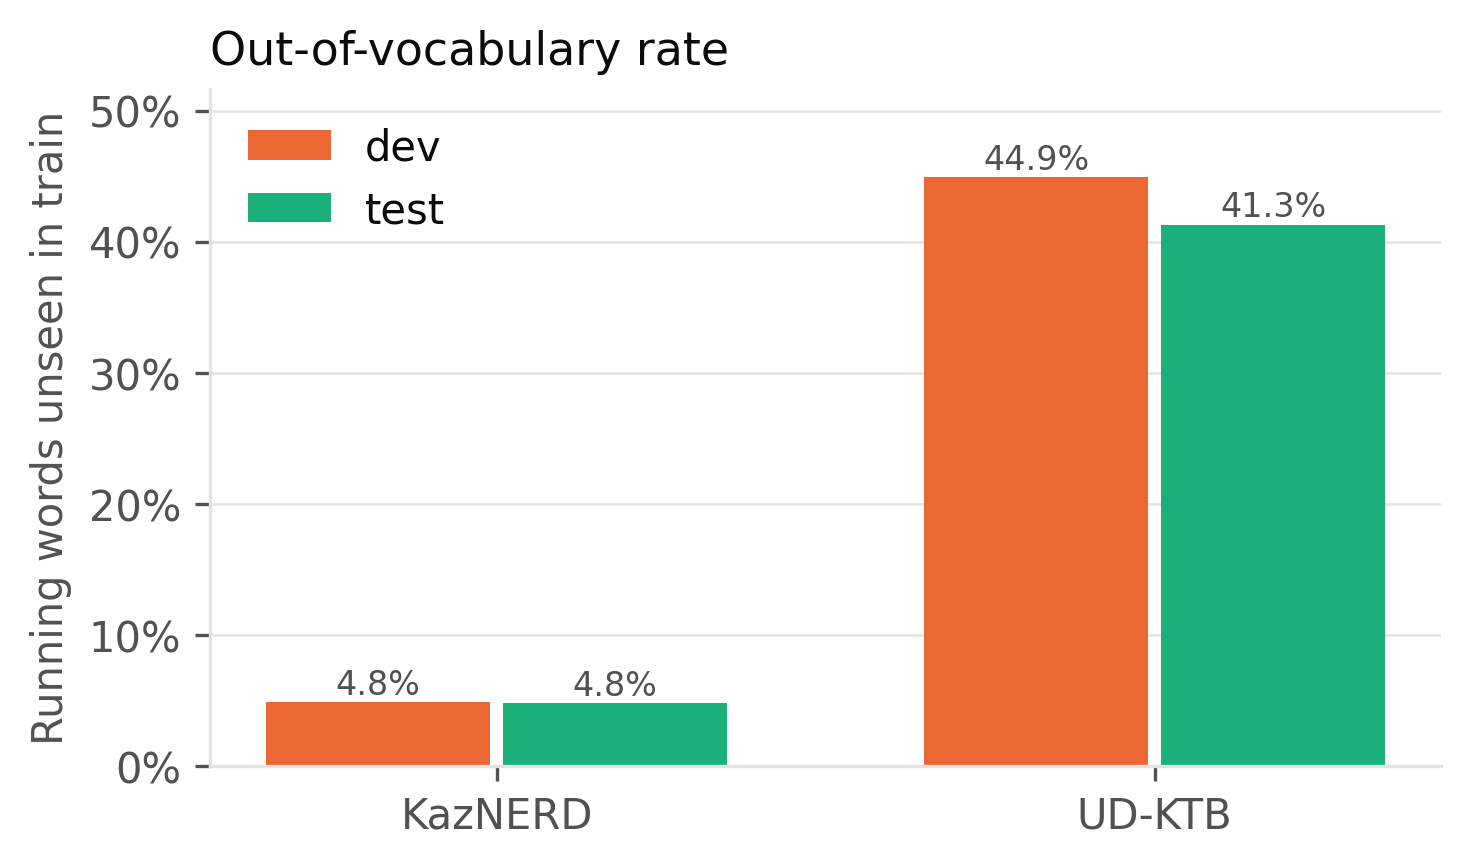

In [10]:
figs = P.step_visualise(ctx)
for i, (name, caption) in enumerate(figs.items(), 1):
    display(Markdown(f'**Figure {i}.** {caption}'))
    display(Image(filename=str(ctx.figures / f'{name}.png'), width=760))

### 8.7 Interpretation of results
Для данных — выводы в конце ноутбука. Для результатов моделей: каждый исследовательский вопрос
решается **внутри одной задачи** на одном тесте; приводится разница с 95% ДИ и p-value с поправкой
Холма (`src/eval/significance.py`), а также разбивка ошибок по OOV, длине и источнику
(`src/eval/breakdown.py`).

### 8.8 Creating a report
Отчёт собирается из результатов, поэтому цифры в нём всегда актуальны.

In [11]:
path = P.step_report(ctx)
print('HTML (для просмотра):', path)
print('Markdown (для диссертации):', ctx.out / 'report.md')

HTML (для просмотра): /content/drive/MyDrive/thesis/outputs/stage1_data/report.html
Markdown (для диссертации): /content/drive/MyDrive/thesis/outputs/stage1_data/report.md


### 8.9 Secrecy and confidentiality · 8.10 Documentation
Персональные данные не собираются; корпуса открытые (CC BY 4.0, CC BY-SA 4.0), используются со ссылкой
на авторов. Данные — на Google Drive, не в git; код — в приватном репозитории; токен — в Colab Secrets.
Журнал запуска: версии, лицензии, хэши, время каждого шага.

In [12]:
log = P.step_document(ctx, timings=[])
print(json.dumps({k: log[k] for k in ('finished_at', 'code_commit', 'sources', 'storage')}, ensure_ascii=False, indent=1))

{
 "finished_at": "2026-10-27T15:26:14+00:00",
 "code_commit": "276393c",
 "sources": {
  "kaznerd": {
   "version": "commit bd4333d (2025-01-15)",
   "license": "CC BY 4.0",
   "citation": "Yeshpanov et al., 2022. KazNERD: Kazakh Named Entity Recognition Dataset. LREC."
  },
  "ud-ktb": {
   "version": "release r2.18",
   "license": "CC BY-SA 4.0",
   "citation": "Makazhanov et al., 2015; Tyers & Washington, 2015. UD Kazakh KTB."
  }
 },
 "storage": {
  "raw_and_processed_data": "Google Drive (not in git)",
  "code": "private GitHub repository",
  "credentials": "GitHub token in Colab Secrets, never in code"
 }
}


### 8.11 Publication of results
Диссертация; после защиты — код и номера разбиений (не сами данные) в открытом репозитории;
по согласованию с руководителем — короткая статья.

---

## Выводы по данным

1. **Масштаб:** KazNERD — 112 702 предложения (≈1,3 млн токенов), UD-KTB — 1 078 (≈10,5 тыс. слов):
   разница на два порядка, задуманный контраст «больше / мало ресурсов».
2. **Качество высокое:** ошибок формата нет; исправлено 76 латинских букв-двойников и 16 тегов IOB2.
   Предложения не удалялись.
3. **Сплит UD-KTB пересобран:** официальный train — 31 предложение из других текстов, чем test;
   новый 864 / 107 / 107 с одинаковым жанровым составом.
4. **Дисбаланс:** CARDINAL, DATE и GPE ≈ 53% сущностей; NON_HUMAN — 6 в train (≈3900:1). Поэтому
   кроме micro-F1 — macro-F1 и F1 по классам.
5. **Редкие слова — главная трудность UD-KTB:** 41–45% словоупотреблений dev/test нет в train
   (KazNERD — 4,8%). Это прямая мотивация морфологических правил в гибриде.
6. **Морфология:** 319 наборов FEATS, треть — единичные; неизвестных наборов в test ≈1,6%.
7. **KazNERD:** 2,7% test есть в train, 19 противоречий, кандидаты в пропуски сущностей —
   официальный сплит сохранён, эти цифры указываются в главе о данных.